In [1]:
import numpy as np, rasterio, matplotlib.pyplot as plt, geopandas as gpd
from rasterio.features import geometry_mask
from matplotlib.colors import LightSource, TwoSlopeNorm

R="../data/rasters/"
paths={"elev":R+"canwell_domainlong_elev2010_5m.tif", "slope":R+"canwell_domainlong_slope2010_5m.tif",
       "aspect":R+"canwell_domainlong_aspect2010_5m.tif", "tpi":R+"canwell_domainlong_tpi2010_5m.tif",
       "ndvi":R+"canwell_domainlong_ndvi2010_5m.tif", "lst":R+"canwell_domainlong_lst2010_5m.tif",
       "pddem":R+"canwell_domainlong_ddem_2010_2000_5m.tif", "fddem":R+"canwell_domainlong_ddem_2025_2010_5m.tif"}
SLOPE_GPKG="../data/outlines/ncanwell_longslope_nolap.gpkg"
BASIN_GPKG="../data/outlines/ncanwell_longbasin_nolap.gpkg"

def load(p):
    with rasterio.open(p) as s: a=s.read(1).astype(float); nod=s.nodata
    a[(a==nod)|(~np.isfinite(a))|(a<-1e30)]=np.nan; return a

with rasterio.open(paths["elev"]) as s: T=s.transform; H,W=s.height,s.width
extent=(T.c, T.c+W*T.a, T.f+H*T.e, T.f)
slope_mask=geometry_mask(gpd.read_file(SLOPE_GPKG).geometry, (H,W), T, invert=True)
basin_mask=geometry_mask(gpd.read_file(BASIN_GPKG).geometry, (H,W), T, invert=True)
domain_mask=slope_mask|basin_mask
dem=load(paths["elev"]); hs=LightSource(315,45).hillshade(np.nan_to_num(dem,nan=np.nanmin(dem)), vert_exag=2)
print('loaded')

loaded


In [24]:
# helper cell for scale bar and north arrow

from mpl_toolkits.axes_grid1.anchored_artists import AnchoredSizeBar
import matplotlib.font_manager as fm, matplotlib.patheffects as pe

def scalebar(ax, length_m, label, loc="lower right"):
    ax.add_artist(AnchoredSizeBar(ax.transData, length_m, label, loc, pad=0.4,
                  color="k", frameon=True, size_vertical=length_m*0.02,
                  fontproperties=fm.FontProperties(size=9)))

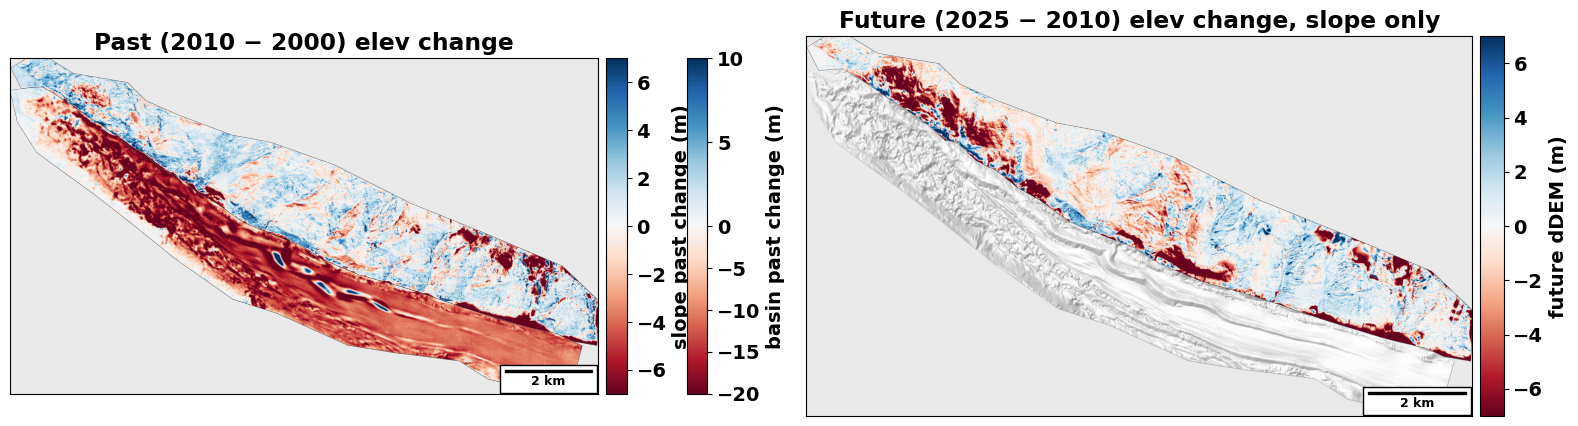

In [27]:
from mpl_toolkits.axes_grid1 import make_axes_locatable

pddem, fddem = load(paths["pddem"]), load(paths["fddem"])
S_LO,S_HI = -7, 7      # slope past range  (tune)
B_LO,B_HI = -20, 10     # basin past range  (tune: Canwell thinning is large/negative)
F_LO,F_HI = -7, 7      # slope future range (tune)

# Set global font size and bold weight
plt.rcParams.update({
    'font.size': 14,
    'font.weight': 'bold',
    'axes.labelweight': 'bold',
    'axes.titleweight': 'bold',
    'figure.titleweight': 'bold'
})

fig,(axp,axf)=plt.subplots(1,2,figsize=(16,7))

axp.imshow(hs,cmap="gray",extent=extent,origin="upper",alpha=0.5)
im_s=axp.imshow(np.ma.masked_where(~slope_mask,pddem), cmap="RdBu", norm=TwoSlopeNorm(0,S_LO,S_HI), extent=extent,origin="upper")
im_b=axp.imshow(np.ma.masked_where(~basin_mask,pddem), cmap="RdBu", norm=TwoSlopeNorm(0,B_LO,B_HI), extent=extent,origin="upper")
#fig.colorbar(im_s,ax=axp,fraction=0.046,pad=0.02).set_label("slope past dDEM (m)")
#fig.colorbar(im_b,ax=axp,fraction=0.046,pad=0.14).set_label("basin past dDEM (m)")
axp.set_title("Past (2010 − 2000) elev change")

axf.imshow(hs,cmap="gray",extent=extent,origin="upper",alpha=0.5)
im_f=axf.imshow(np.ma.masked_where(~slope_mask,fddem), cmap="RdBu", norm=TwoSlopeNorm(0,F_LO,F_HI), extent=extent,origin="upper")
# --- past panel: two well-separated colorbars ---
div = make_axes_locatable(axp)
cax1 = div.append_axes("right", size="3.5%", pad=0.08)   # slope bar (inner)
cax2 = div.append_axes("right", size="3.5%", pad=0.60)   # basin bar (outer); bump pad to separate
cb1 = fig.colorbar(im_s, cax=cax1)
cb1.ax.yaxis.set_ticks_position("right"); cb1.ax.yaxis.set_label_position("right")  # push inner bar's labels toward the map
cb1.set_label("slope past change (m)")
fig.colorbar(im_b, cax=cax2).set_label("basin past change (m)")

# --- future panel: single colorbar, matched style ---
caxf = make_axes_locatable(axf).append_axes("right", size="3.5%", pad=0.08)
fig.colorbar(im_f, cax=caxf).set_label("future dDEM (m)")
axf.set_title("Future (2025 − 2010) elev change, slope only")

scalebar(axp, 2000, "2 km", loc="lower right")
scalebar(axf, 2000, "2 km", loc="lower right")

# --- strip easting/northing (located in the other figure) ---
for ax in (axp, axf):
    ax.set_xticks([]); ax.set_yticks([]); ax.set_xlabel(""); ax.set_ylabel("")

plt.tight_layout()
# plt.savefig("../figures/fig_ddem.png",dpi=200,bbox_inches="tight")
plt.show()

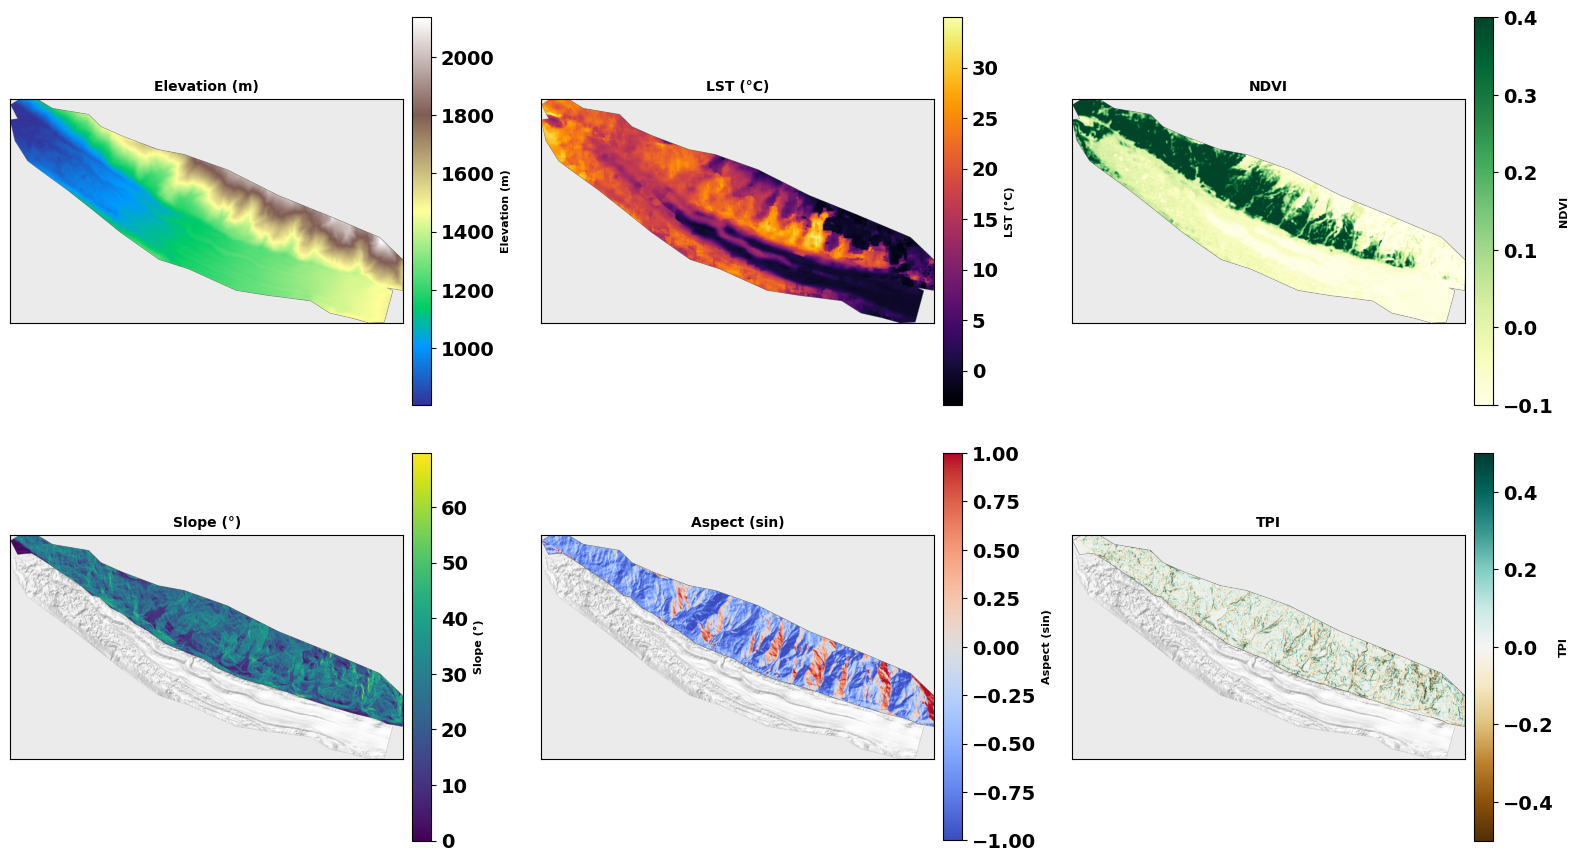

In [23]:
asp=load(paths["aspect"]); aspect_sin=np.where((~np.isfinite(asp))|(asp==-9999), np.nan, np.sin(np.deg2rad(asp)))

def panel(ax, data, mask, cmap, label, **kw):
    ax.imshow(hs,cmap="gray",extent=extent,origin="upper",alpha=0.45)
    m=np.ma.masked_where((~mask)|(~np.isfinite(data)), data)
    im=ax.imshow(m,cmap=cmap,extent=extent,origin="upper",**kw)
    ax.figure.colorbar(im,ax=ax,fraction=0.046,pad=0.02).set_label(label,fontsize=8)
    ax.set_title(label,fontsize=10); ax.set_xticks([]); ax.set_yticks([])

fig,ax=plt.subplots(2,3,figsize=(16,9))
panel(ax[0,0], load(paths["elev"]), domain_mask, "terrain", "Elevation (m)")
panel(ax[0,1], load(paths["lst"]),  domain_mask, "inferno", "LST (°C)")
panel(ax[0,2], load(paths["ndvi"]), domain_mask, "YlGn",    "NDVI", vmin=-0.1, vmax=0.4)
panel(ax[1,0], load(paths["slope"]),slope_mask,  "viridis", "Slope (°)")
panel(ax[1,1], aspect_sin,          slope_mask,  "coolwarm","Aspect (sin)", vmin=-1, vmax=1)
panel(ax[1,2], load(paths["tpi"]),  slope_mask,  "BrBG",    "TPI", norm=TwoSlopeNorm(0,-0.5,0.5))
plt.tight_layout()
# plt.savefig("../figures/fig_inputs.png",dpi=200,bbox_inches="tight")
plt.show()